# Trabajo Práctico: Laboratorio de Métodos Cuantitativos Aplicados a la Gestión
**Materia:** Laboratorio de Métodos Cuantitativos Aplicados a la Gestión (FCE UBA)  
**Dataset:** DataCo Smart Supply Chain  

Esta notebook unificada integra todo el trabajo del grupo: la exploración inicial, la limpieza y validación de datos a nivel de pedido, el análisis estadístico descriptivo y comparativo, y el análisis gráfico avanzado con sus respectivas interpretaciones económicas.

# SECCIÓN 1 - CARGA, EXPLORACIÓN E INVENTARIO INICIAL DE DATOS

En esta primera sección se realiza la importación de las librerías necesarias para el análisis y la carga remota del dataset oficial desde el repositorio de GitHub. A continuación, se ejecuta un primer control exploratorio para auditar la estructura general, las dimensiones del dataset, la cobertura temporal y geográfica, así como la presencia de valores faltantes y filas duplicadas antes de proceder con las transformaciones de datos.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización para claridad en decimales y columnas
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Carga remota del dataset desde la URL raw de GitHub con encoding latin-1
url_raw = "https://raw.githubusercontent.com/JuanchiWienberg/TP---LAB.-DE-MET.-CUANT.-APLICADOS-A-LA-GEST./main/DataCoSupplyChainDataset.csv"
df = pd.read_csv(url_raw, encoding="latin-1")

print("Materia prima cargada con éxito. Filas originales:", df.shape[0])
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas\n")

print("--- PRIMERAS 5 FILAS (HEAD) ---")
display(df.head())

print("--- INFORMACIÓN DE COLUMNAS Y TIPOS DE DATOS ---")
df.info()

# Cobertura temporal
if "order date (DateOrders)" in df.columns:
    df["order date (DateOrders)"] = pd.to_datetime(df["order date (DateOrders)"], errors="coerce")
    print(f"\nPeríodo temporal cubierto: {df['order date (DateOrders)'].min()} a {df['order date (DateOrders)'].max()}")

# Cobertura geográfica
if "Order Region" in df.columns:
    print(f"Regiones comerciales representadas ({df['Order Region'].nunique()} en total):")
    print(df["Order Region"].unique())

# Evaluación de calidad inicial
nulos = df.isnull().sum()
print("\n--- COLUMNAS CON VALORES NULOS ---")
print(nulos[nulos > 0])

duplicados = df.duplicated().sum()
print(f"\nCantidad de filas totalmente duplicadas: {duplicados}")

print("\n--- ESTADÍSTICAS DESCRIPTIVAS INICIALES ---")
display(df.describe().T)

Materia prima cargada con éxito. Filas originales: 180519
Dimensiones del dataset: 180519 filas y 53 columnas

--- PRIMERAS 5 FILAS (HEAD) ---


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.25,314.64,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.11,0.04,180517,327.75,0.29,1,327.75,314.64,91.25,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.09,311.36,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.00,2,Fitness,18.28,-66.04,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.39,0.05,179254,327.75,-0.80,1,327.75,311.36,-249.09,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.78,309.72,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,"95,125.00",2,Fitness,37.29,-121.88,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.03,0.06,179253,327.75,-0.80,1,327.75,309.72,-247.78,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.86,304.81,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,"90,027.00",2,Fitness,34.13,-118.29,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.94,0.07,179252,327.75,0.08,1,327.75,304.81,22.86,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.21,298.25,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.50,0.09,179251,327.75,0.45,1,327.75,298.25,134.21,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


--- INFORMACIÓN DE COLUMNAS Y TIPOS DE DATOS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-

,count,mean,min,25%,50%,75%,max,std
Days for shipping (real),"180,519.00",3.50,0.00,2.00,3.00,5.00,6.00,1.62
Days for shipment (scheduled),"180,519.00",2.93,0.00,2.00,4.00,4.00,4.00,1.37
Benefit per order,"180,519.00",21.97,"-4,274.98",7.00,31.52,64.80,911.80,104.43
Sales per customer,"180,519.00",183.11,7.49,104.38,163.99,247.40,"1,939.99",120.04
Late_delivery_risk,"180,519.00",0.55,0.00,0.00,1.00,1.00,1.00,0.50
Category Id,"180,519.00",31.85,2.00,18.00,29.00,45.00,76.00,15.64
Customer Id,"180,519.00","6,691.38",1.00,"3,258.50","6,457.00","9,779.00","20,757.00","4,162.92"
Customer Zipcode,"180,516.00","35,921.13",603.00,725.00,"19,380.00","78,207.00","99,205.00","37,542.46"
Department Id,"180,519.00",5.44,2.00,4.00,5.00,7.00,12.00,1.63
Latitude,"180,519.00",29.72,-33.94,18.27,33.14,39.28,48.78,9.81


## Pregunta de Investigación Central

1. **¿Cuál es la pregunta?**  
   ¿En qué medida el riesgo de entregas tardías (`Late_delivery_risk`) afecta el margen de ganancia operativa en los diferentes segmentos de clientes y regiones comerciales de DataCo?

2. **¿Por qué vale la pena responderla?**  
   Permite identificar si las fallas en los tiempos logísticos están erosionando la rentabilidad operativa de la empresa de forma diferenciada según el mercado o el perfil del cliente.

---
# SECCIÓN 2 — Preparación y validación de los datos

Esta sección continúa el trabajo de exploración inicial. Revisa la unidad de análisis, justifica las transformaciones necesarias y deja una tabla con un registro por pedido para el análisis posterior.

## Etapa 0 — Punto de partida y decisiones pendientes
La exploración inicial registró 180.519 filas y 53 columnas, sin filas completamente duplicadas. Antes de comparar ganancias, debemos tener en cuenta que la base está organizada por artículos de pedido: un mismo `Order Id` puede aparecer en varias filas. Por eso, la tabla original no debe tratarse directamente como si cada fila fuera un pedido.

In [13]:
# 1.1. Comprobar cuántas filas tiene cada pedido
filas_por_pedido = df.groupby("Order Id").size()

print(f"Filas de la base original: {len(df):,}")
print(f"Pedidos únicos: {df['Order Id'].nunique():,}")
print(f"Pedidos con una sola fila: {(filas_por_pedido == 1).sum():,}")
print(f"Pedidos con varias filas: {(filas_por_pedido > 1).sum():,}")
print(f"Máximo de filas para un pedido: {filas_por_pedido.max()}")

# 1.2. Revisar un pedido con varias filas
id_ejemplo = filas_por_pedido[filas_por_pedido > 1].index[0]

columnas_ejemplo = [
    "Order Id",
    "Order Item Id",
    "Order Item Quantity",
    "Order Item Total",
    "Order Item Profit Ratio",
    "Order Profit Per Order",
    "Benefit per order",
    "Delivery Status"
]

display(
    df.loc[df["Order Id"] == id_ejemplo, columnas_ejemplo]
    .sort_values("Order Item Id")
)

# 1.3. Comprobar qué variables se mantienen constantes dentro de cada pedido
variables_constantes = [
    "Late_delivery_risk",
    "Delivery Status",
    "Customer Segment",
    "Order Region"
]

print("¿Coinciden Order Profit Per Order y Benefit per order en todas las filas?")
print(df["Order Profit Per Order"].eq(df["Benefit per order"]).all())

print("\nCantidad máxima de valores distintos por pedido:")
display(
    df.groupby("Order Id")[variables_constantes]
    .nunique(dropna=False)
    .max()
    .to_frame("Máximo de valores distintos")
)

print("\n¿Order Item Id identifica cada fila?")
print(f"Valores únicos de Order Item Id: {df['Order Item Id'].nunique():,}")
print(f"Filas de la base: {len(df):,}")

Filas de la base original: 180,519
Pedidos únicos: 65,752
Pedidos con una sola fila: 19,850
Pedidos con varias filas: 45,902
Máximo de filas para un pedido: 5


,Order Id,Order Item Id,Order Item Quantity,Order Item Total,Order Item Profit Ratio,Order Profit Per Order,Benefit per order,Delivery Status
77011,2,2,1,193.99,0.47,91.18,91.18,Advance shipping
109322,2,3,5,227.50,0.30,68.25,68.25,Advance shipping
87884,2,4,1,107.89,0.34,36.47,36.47,Advance shipping


¿Coinciden Order Profit Per Order y Benefit per order en todas las filas?
True

Cantidad máxima de valores distintos por pedido:


,Máximo de valores distintos
Late_delivery_risk,1
Delivery Status,1
Customer Segment,1
Order Region,1



¿Order Item Id identifica cada fila?
Valores únicos de Order Item Id: 180,519
Filas de la base: 180,519


### 1.4. Revisar valores negativos y posibles outliers
Antes de construir una tabla por pedido, revisamos los valores negativos de las variables económicas y detectamos posibles valores atípicos mediante el rango intercuartílico (IQR). Estos controles son exploratorios: una ganancia negativa puede representar una pérdida real y un valor extremo no es necesariamente un error. No eliminamos observaciones automáticamente.

In [14]:
columnas_economicas = [
    "Order Item Total",
    "Order Item Profit Ratio",
    "Order Profit Per Order",
    "Benefit per order",
    "Sales per customer"
]

resumen_negativos = []
for columna in columnas_economicas:
    valores = pd.to_numeric(df[columna], errors="coerce")
    resumen_negativos.append({
        "variable": columna,
        "negativos": int((valores < 0).sum()),
        "porcentaje_negativo": float((valores < 0).mean() * 100),
        "mínimo": valores.min(),
        "máximo": valores.max()
    })

display(pd.DataFrame(resumen_negativos).round(4))

# Contraste numérico exploratorio entre ganancia registrada y total por ratio.
ganancia_calculada = df["Order Item Total"] * df["Order Item Profit Ratio"]
diferencia = (df["Order Profit Per Order"] - ganancia_calculada).abs()
print("Diferencia absoluta entre Order Profit Per Order y Order Item Total * Order Item Profit Ratio:")
display(diferencia.describe().to_frame("diferencia_absoluta").round(4))
print(f"Filas con diferencia absoluta <= 0,02: {(diferencia <= 0.02).sum():,} ({(diferencia <= 0.02).mean()*100:.1f}%)")
print("La relación no es exacta en todas las filas; no se reemplaza la variable original por esta fórmula.")

# Detección exploratoria de outliers mediante IQR.
resumen_outliers = []
for columna in columnas_economicas:
    valores = pd.to_numeric(df[columna], errors="coerce").dropna()
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1
    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr
    cantidad = int(((valores < inferior) | (valores > superior)).sum())
    resumen_outliers.append({
        "variable": columna,
        "límite_inferior_IQR": inferior,
        "límite_superior_IQR": superior,
        "posibles_outliers": cantidad,
        "porcentaje": cantidad / len(valores) * 100
    })

display(pd.DataFrame(resumen_outliers).round(4))

,variable,negativos,porcentaje_negativo,mínimo,máximo
0,Order Item Total,0,0.00,7.49,"1,939.99"
1,Order Item Profit Ratio,33784,18.71,-2.75,0.50
2,Order Profit Per Order,33784,18.71,"-4,274.98",911.80
3,Benefit per order,33784,18.71,"-4,274.98",911.80
4,Sales per customer,0,0.00,7.49,"1,939.99"


Diferencia absoluta entre Order Profit Per Order y Order Item Total * Order Item Profit Ratio:


,diferencia_absoluta
count,"180,519.00"
mean,0.22
std,0.41
min,0.00
25%,0.00
50%,0.00
75%,0.33
max,9.30


Filas con diferencia absoluta <= 0,02: 115,474 (64.0%)
La relación no es exacta en todas las filas; no se reemplaza la variable original por esta fórmula.


,variable,límite_inferior_IQR,límite_superior_IQR,posibles_outliers,porcentaje
0,Order Item Total,-110.15,461.93,1943,1.08
1,Order Item Profit Ratio,-0.34,0.78,17300,9.58
2,Order Profit Per Order,-79.70,151.50,18942,10.49
3,Benefit per order,-79.70,151.50,18942,10.49
4,Sales per customer,-110.15,461.93,1943,1.08


**Decisión metodológica:** no se eliminan ganancias negativas ni posibles outliers por el solo hecho de ser negativos o extremos. La variable `Order Profit Per Order` se agrega por `Order Id` como suma de los importes registrados en las filas del pedido, interpretándola como una medida derivada de los registros de artículos.

## Etapa 2 — Preparar las variables necesarias
Trabajamos sobre una copia para conservar intacto el DataFrame original. Normalizamos los espacios sobrantes en `Order Region` y convertimos las fechas a tipo fecha.

In [15]:
df_base_preparada = df.copy()

# Normalizar espacios sobrantes en la región
df_base_preparada["Order Region"] = df_base_preparada["Order Region"].astype("string").str.strip()

# Convertir fechas sin alterar el DataFrame original
columnas_fecha = [
    "order date (DateOrders)",
    "shipping date (DateOrders)"
]

for columna in columnas_fecha:
    if columna in df_base_preparada.columns:
        df_base_preparada[columna] = pd.to_datetime(
            df_base_preparada[columna],
            errors="coerce"
        )

print("Dimensiones después de preparar la copia:", df_base_preparada.shape)
print("¿Order Item Id identifica cada fila?", df_base_preparada["Order Item Id"].is_unique)
print("Cantidad de regiones después de quitar espacios:", df_base_preparada["Order Region"].nunique())

Dimensiones después de preparar la copia: (180519, 53)
¿Order Item Id identifica cada fila? True
Cantidad de regiones después de quitar espacios: 23


## Etapa 3 — Construir una tabla con un registro por pedido
Agrupamos las filas por `Order Id`. Sumamos los importes de ganancia registrados y `Order Item Total` para construir medidas agregadas por pedido, previa comprobación de consistencia.

In [16]:
variables_esperadas_constantes = [
    "Late_delivery_risk", "Delivery Status", "Customer Segment",
    "Order Region", "Order Status", "order date (DateOrders)"
]
consistencia_pedido = df_base_preparada.groupby("Order Id")[variables_esperadas_constantes].nunique(dropna=False)
pedidos_inconsistentes = consistencia_pedido.gt(1).any(axis=1)
print(f"Pedidos con inconsistencias en variables que deberían ser constantes: {pedidos_inconsistentes.sum():,}")

if pedidos_inconsistentes.any():
    display(consistencia_pedido.loc[pedidos_inconsistentes].head(10))
    raise ValueError("Hay pedidos con variables inconsistentes. Revisar antes de usar first() en la agregación.")

df_pedidos = (
    df_base_preparada.groupby("Order Id", as_index=False)
    .agg(
        cantidad_filas=("Order Item Id", "size"),
        unidades_totales=("Order Item Quantity", "sum"),
        ganancia_total_pedido=("Order Profit Per Order", "sum"),
        ventas_totales_pedido=("Order Item Total", "sum"),
        riesgo_entrega_tardia=("Late_delivery_risk", "first"),
        estado_entrega=("Delivery Status", "first"),
        segmento_cliente=("Customer Segment", "first"),
        region=("Order Region", "first"),
        fecha_pedido=("order date (DateOrders)", "first"),
        estado_pedido=("Order Status", "first")
    )
)

df_pedidos["margen_ganancia_pedido"] = (
    df_pedidos["ganancia_total_pedido"]
    / df_pedidos["ventas_totales_pedido"].where(
        df_pedidos["ventas_totales_pedido"] != 0
    )
)

print(f"Pedidos en la tabla final: {len(df_pedidos):,}")
print(f"Pedidos únicos: {df_pedidos['Order Id'].nunique():,}")
display(df_pedidos.head())

Pedidos con inconsistencias en variables que deberían ser constantes: 0
Pedidos en la tabla final: 65,752
Pedidos únicos: 65,752


,Order Id,cantidad_filas,unidades_totales,ganancia_total_pedido,ventas_totales_pedido,riesgo_entrega_tardia,estado_entrega,segmento_cliente,region,fecha_pedido,estado_pedido,margen_ganancia_pedido
0,1,1,1,88.79,239.98,0,Advance shipping,Consumer,Central America,2015-01-01 00:00:00,CLOSED,0.37
1,2,3,7,195.90,529.38,0,Advance shipping,Consumer,South America,2015-01-01 00:21:00,PENDING_PAYMENT,0.37
2,4,4,14,124.09,620.87,1,Late delivery,Home Office,South America,2015-01-01 01:03:00,CLOSED,0.20
3,5,5,10,390.09,987.07,1,Late delivery,Consumer,South America,2015-01-01 01:24:00,COMPLETE,0.40
4,7,3,7,203.93,525.52,1,Late delivery,Consumer,South America,2015-01-01 02:06:00,COMPLETE,0.39


## Etapa 4 — Validar la tabla y dejarla lista para el análisis
Los pedidos con estado `Shipping canceled` se mantienen en `df_pedidos` para no perder información. Creamos por separado `df_pedidos_analisis`, que excluye esos pedidos de la comparación de entregas realizadas.

In [17]:
variables_clave = [
    "Order Id",
    "ganancia_total_pedido",
    "ventas_totales_pedido",
    "riesgo_entrega_tardia",
    "estado_entrega",
    "segmento_cliente",
    "region"
]

print("¿Hay un único registro por pedido?")
print(df_pedidos["Order Id"].is_unique)

print("\nCantidad de pedidos por estado de entrega:")
display(
    df_pedidos["estado_entrega"]
    .value_counts(dropna=False)
    .to_frame("Cantidad de pedidos")
)

cantidad_antes = len(df_pedidos)
df_pedidos_analisis = df_pedidos.loc[
    df_pedidos["estado_entrega"] != "Shipping canceled"
].copy()
cantidad_excluida = cantidad_antes - len(df_pedidos_analisis)

print(f"\nPedidos en la tabla completa: {cantidad_antes:,}")
print(f"Pedidos excluidos por envío cancelado: {cantidad_excluida:,}")
print(f"Pedidos disponibles para comparar entregas: {len(df_pedidos_analisis):,}")

display(
    df_pedidos_analisis[
        [
            "ganancia_total_pedido",
            "ventas_totales_pedido",
            "margen_ganancia_pedido",
            "riesgo_entrega_tardia"
        ]
    ].describe().T
)

¿Hay un único registro por pedido?
True

Cantidad de pedidos por estado de entrega:


,Cantidad de pedidos
estado_entrega,
Late delivery,36048
Advance shipping,15127
Shipping on time,11722
Shipping canceled,2855



Pedidos en la tabla completa: 65,752
Pedidos excluidos por envío cancelado: 2,855
Pedidos disponibles para comparar entregas: 62,897


,count,mean,std,min,25%,50%,75%,max
ganancia_total_pedido,"62,897.00",60.52,189.66,"-4,325.85",7.80,72.64,158.77,980.28
ventas_totales_pedido,"62,897.00",503.12,321.29,7.49,244.35,456.87,721.96,"2,768.41"
margen_ganancia_pedido,"62,897.00",0.12,0.37,-2.75,0.05,0.23,0.34,0.50
riesgo_entrega_tardia,"62,897.00",0.57,0.49,0.00,0.00,1.00,1.00,1.00


---
# SECCIÓN 3 — Calcular estadísticas y comparar resultados (Integrante: Sebastián Morán)

En esta sección se desarrolla la parte estadístico-analítica del dataset para alcanzar la respuesta a la pregunta central, calculando estadísticas descriptivas y comparaciones mediante agrupaciones.

In [18]:
# Etapa 1: Estadísticas descriptivas de las variables numéricas clave
variables_numericas = [
    "ventas_totales_pedido",
    "ganancia_total_pedido",
    "margen_ganancia_pedido"
]

estadisticas_descriptivas = df_pedidos_analisis[variables_numericas].describe().T
print("--- Estadísticas descriptivas relevantes ---")
display(estadisticas_descriptivas)

# Etapa 2: Utilizar groupby() para comparar los grupos por estado de entrega
comparación_entrega = (
    df_pedidos_analisis.groupby("estado_entrega")
    .agg(
       cantidad_pedidos=("Order Id", "count"),
       promedio_ventas=("ventas_totales_pedido", "mean"),
       promedio_ganancia=("ganancia_total_pedido", "mean"),
       margen_promedio=("margen_ganancia_pedido", "mean")
    )
   .reset_index()
)
print("--- Comparación por estado de entrega ---")
display(comparación_entrega)

# Etapa 3: Preparar las dos tablas de resultados agrupados
# Tabla 1: Segmento de cliente cruzado con el riesgo de entrega tardía
tabla_segmento_riesgo = (
    df_pedidos_analisis.groupby(["segmento_cliente", "riesgo_entrega_tardia"])
    .agg(
        total_pedidos=("Order Id", "count"),
        ganancia_total=("ganancia_total_pedido", "sum"),
        margen_promedio=("margen_ganancia_pedido", "mean")
    )
    .reset_index()
)
print("--- Tabla 1: Resultados agrupados por Segmento y Riesgo ---")
display(tabla_segmento_riesgo)

# Tabla 2: Resultados agrupados por Región de destino
tabla_region = (
    df_pedidos_analisis.groupby("region")
    .agg(
        total_pedidos=("Order Id", "count"),
        ventas_totales=("ventas_totales_pedido", "sum"),
        ganancia_promedio=("ganancia_total_pedido", "mean")
    )
    .reset_index()
    .sort_values(by="total_pedidos", ascending=False)
)
print("\n--- Tabla 2: Resultados agrupados por Región ---")
display(tabla_region)

--- Estadísticas descriptivas relevantes ---


,count,mean,std,min,25%,50%,75%,max
ventas_totales_pedido,"62,897.00",503.12,321.29,7.49,244.35,456.87,721.96,"2,768.41"
ganancia_total_pedido,"62,897.00",60.52,189.66,"-4,325.85",7.80,72.64,158.77,980.28
margen_ganancia_pedido,"62,897.00",0.12,0.37,-2.75,0.05,0.23,0.34,0.50


--- Comparación por estado de entrega ---


,estado_entrega,cantidad_pedidos,promedio_ventas,promedio_ganancia,margen_promedio
0,Advance shipping,15127,506.14,61.82,0.12
1,Late delivery,36048,501.62,59.37,0.12
2,Shipping on time,11722,503.82,62.37,0.12


--- Tabla 1: Resultados agrupados por Segmento y Riesgo ---


,segmento_cliente,riesgo_entrega_tardia,total_pedidos,ganancia_total,margen_promedio
0,Consumer,0,13942,"860,084.40",0.12
1,Consumer,1,18672,"1,122,779.22",0.12
2,Corporate,0,8146,"520,738.79",0.12
3,Corporate,1,10871,"637,082.25",0.12
4,Home Office,0,4761,"285,545.76",0.13
5,Home Office,1,6505,"380,190.21",0.12



--- Tabla 2: Resultados agrupados por Región ---


,region,total_pedidos,ventas_totales,ganancia_promedio
22,Western Europe,9563,"5,056,355.21",63.51
3,Central America,9001,"4,884,996.05",65.17
12,South America,4738,"2,528,275.12",66.59
11,Oceania,4175,"1,736,607.78",46.80
15,Southeast Asia,4173,"1,665,459.92",48.46
10,Northern Europe,3564,"1,864,435.59",63.53
17,Southern Europe,3390,"1,755,487.58",65.29
13,South Asia,3219,"1,347,836.99",49.32
7,Eastern Asia,3171,"1,282,401.20",44.70
1,Caribbean,2675,"1,416,576.00",62.42


> **Nota metodológica:** Las agrupaciones y comparaciones realizadas mediante `groupby()` y estadísticas descriptivas muestran asociaciones y patrones observados en los datos históricos. Sin embargo, no implican una relación causal directa (no se puede afirmar categóricamente que el retraso cause por sí solo cada pérdida). Los datos son de naturaleza estrictamente descriptiva.

---
# SECCIÓN 4 — Análisis Gráfico

En esta sección se desarrolla el análisis visual y la exploración gráfica del dataset para responder de manera directa a la pregunta central de investigación, empleando un boxplot, un gráfico de barras agrupadas y una matriz de calor.

In [19]:
df_pedidos_analisis.info()
display(df_pedidos_analisis.describe().T)

<class 'pandas.core.frame.DataFrame'>
Index: 62897 entries, 0 to 65751
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Order Id                62897 non-null  int64         
 1   cantidad_filas          62897 non-null  int64         
 2   unidades_totales        62897 non-null  int64         
 3   ganancia_total_pedido   62897 non-null  float64       
 4   ventas_totales_pedido   62897 non-null  float64       
 5   riesgo_entrega_tardia   62897 non-null  int64         
 6   estado_entrega          62897 non-null  object        
 7   segmento_cliente        62897 non-null  object        
 8   region                  62897 non-null  string        
 9   fecha_pedido            62897 non-null  datetime64[ns]
 10  estado_pedido           62897 non-null  object        
 11  margen_ganancia_pedido  62897 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(4), object(

,count,mean,min,25%,50%,75%,max,std
Order Id,"62,897.00","39,312.42",1.00,"19,720.00","39,457.00","59,082.00","77,204.00","22,603.55"
cantidad_filas,"62,897.00",2.75,1.00,1.00,3.00,4.00,5.00,1.48
unidades_totales,"62,897.00",5.84,1.00,2.00,5.00,9.00,24.00,4.17
ganancia_total_pedido,"62,897.00",60.52,"-4,325.85",7.80,72.64,158.77,980.28,189.66
ventas_totales_pedido,"62,897.00",503.12,7.49,244.35,456.87,721.96,"2,768.41",321.29
riesgo_entrega_tardia,"62,897.00",0.57,0.00,0.00,1.00,1.00,1.00,0.49
fecha_pedido,62897,2016-07-27 20:31:59.193920,2015-01-01 00:00:00,2015-10-15 20:26:00,2016-07-29 23:11:00,2017-05-12 10:42:00,2018-01-31 23:38:00,NaN
margen_ganancia_pedido,"62,897.00",0.12,-2.75,0.05,0.23,0.34,0.50,0.37


### Gráfico 1: Evaluación de la Distribución del Margen según Alerta Logística
**Objetivo metodológico:** Evaluar la distribución, la dispersión intercuartílica y la presencia de asimetrías o pérdidas en el margen operativo porcentual de los pedidos, contrastando el escenario normal (Sin Riesgo) contra el escenario ineficiente (Con Riesgo).

/tmp/ipykernel_2247/3937511228.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


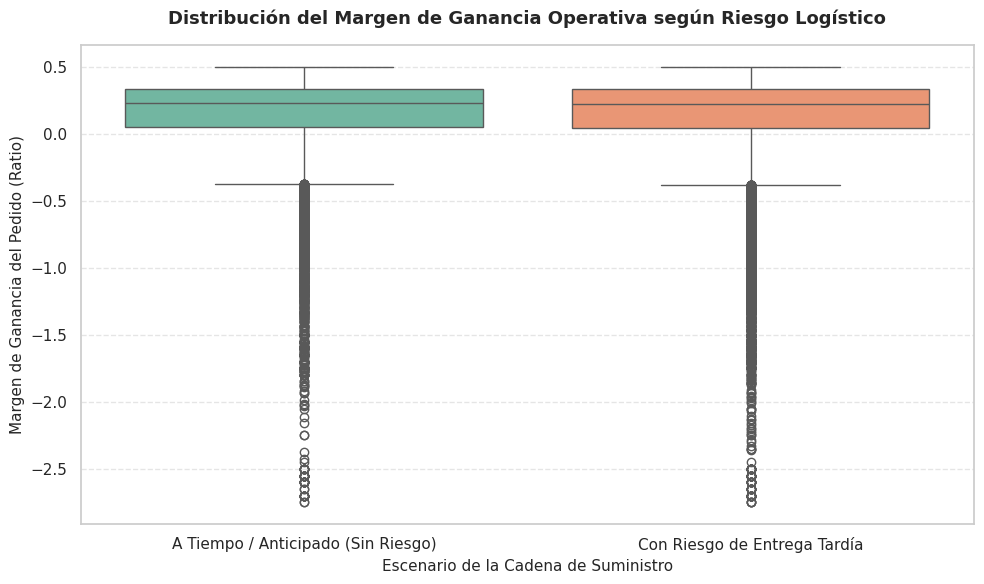

In [20]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="riesgo_entrega_tardia",
    y="margen_ganancia_pedido",
    data=df_pedidos_analisis,
    palette="Set2",
    showfliers=True
)

plt.title("Distribución del Margen de Ganancia Operativa según Riesgo Logístico", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Escenario de la Cadena de Suministro", fontsize=11)
plt.ylabel("Margen de Ganancia del Pedido (Ratio)", fontsize=11)
plt.xticks([0, 1], ["A Tiempo / Anticipado (Sin Riesgo)", "Con Riesgo de Entrega Tardía"])
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("grafico1_boxplot_margen.png", bbox_inches='tight', dpi=300)
plt.show()

### Interpretación Económica del Gráfico 1
El gráfico de cajas muestra que, en promedio, la ganancia normal de un pedido se mantiene en un 12%, sin importar si llega a tiempo o tarde. Esto pasa porque el precio de venta del producto ya está fijo desde el principio en la orden de compra.

Sin embargo, al mirar los puntos sueltos en el gráfico (los valores extremos), se descubre el verdadero peligro para el negocio: cuando hay problemas o retrasos logísticos, aparecen pérdidas de dinero muy grandes que caen hacia el terreno negativo. Esto significa que, aunque el pedido común parece estable, los retrasos terminan desgastando y bajando las ganancias totales de la empresa debido a los costos extras que generan las devoluciones, las quejas de los clientes y la logística inversa.

### Gráfico 2: Análisis de Brecha de Rentabilidad por Segmento de Cliente
**Objetivo metodológico:** Romper el agregado global mediante un gráfico de barras agrupadas (*Grouped Bar Chart*) para identificar si la ineficiencia logística castiga el margen de ganancia operativa de forma diferenciada según el perfil comercial del comprador (Consumer, Corporate, Home Office).

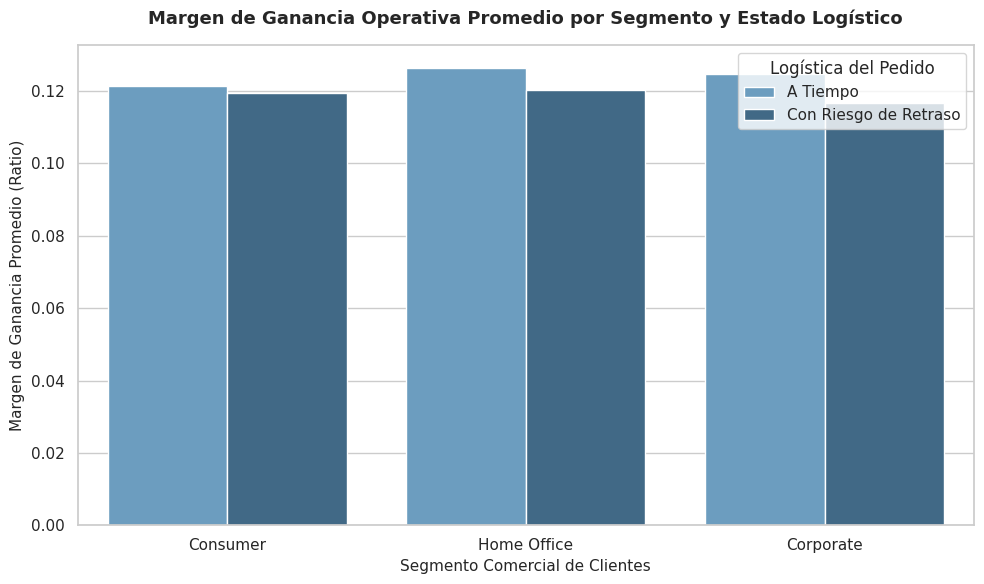

In [21]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x="segmento_cliente",
    y="margen_ganancia_pedido",
    hue="riesgo_entrega_tardia",
    data=df_pedidos_analisis,
    palette="Blues_d",
    errorbar=None
)

plt.title("Margen de Ganancia Operativa Promedio por Segmento y Estado Logístico", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Segmento Comercial de Clientes", fontsize=11)
plt.ylabel("Margen de Ganancia Promedio (Ratio)", fontsize=11)
plt.legend(title="Logística del Pedido", labels=["A Tiempo", "Con Riesgo de Retraso"])

plt.tight_layout()
plt.savefig("grafico2_barras_segmentos.png", bbox_inches='tight', dpi=300)
plt.show()

### Interpretación Económica del Gráfico 2
Al mirar el gráfico de barras, vemos que la ganancia promedio se mantiene casi idéntica (entre el 11% y el 13%) en los tres grupos de clientes: Consumer, Corporate y Home Office. Esto pasa tanto en los envíos que llegan bien como en los que tienen riesgo de retraso.

Sin embargo, hay que tener mucho cuidado con esta conclusión preliminar. Como este gráfico muestra el **promedio**, está ocultando las pérdidas individuales graves que descubrimos en el gráfico de cajas anterior. La ganancia promedio parece estable porque el precio inicial está fijo por contrato, pero las ineficiencias logísticas generan costos ocultos de transporte que dañan la caja general de la empresa, afectando a todos los segmentos por igual una vez que los pedidos salen del depósito.

### Gráfico 3: Matriz de Calor Territorial de Rendimiento Económico e Ineficiencia
**Objetivo metodológico:** Aislar el impacto geográfico cruzando las 10 regiones comerciales líderes en volumen con el estado de riesgo mediante una matriz de calor (*Matrix Heatmap*) de doble entrada.

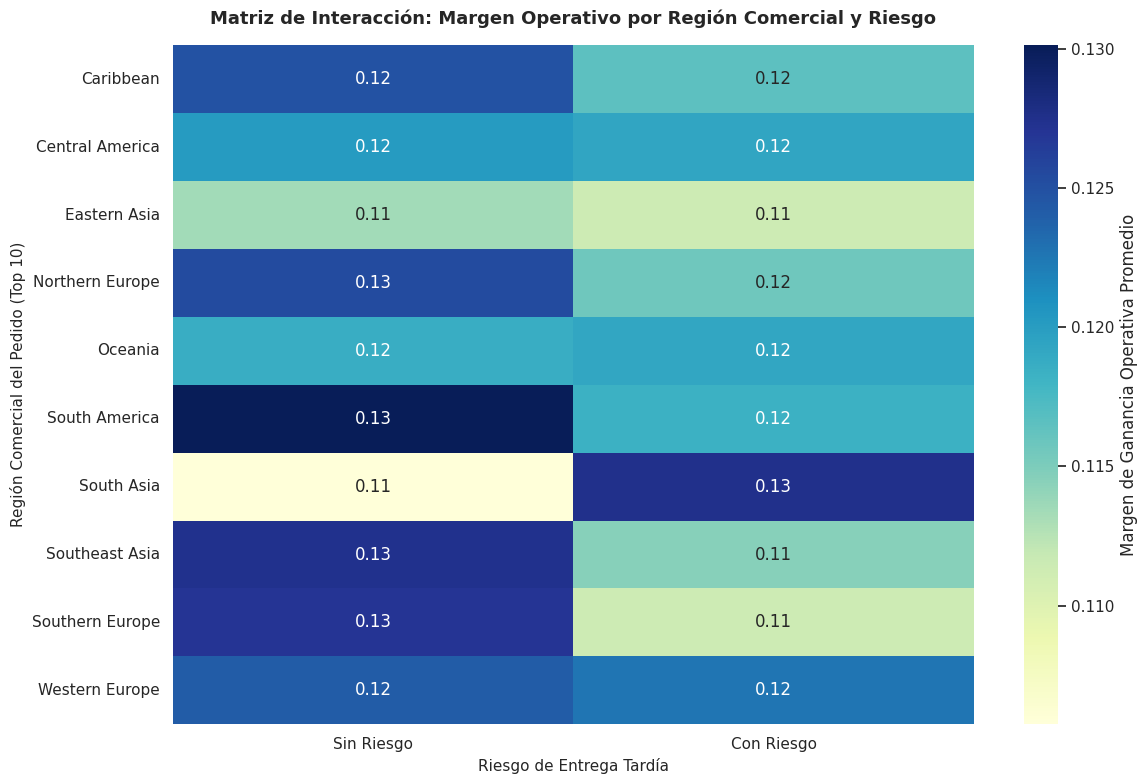

In [22]:
plt.figure(figsize=(12, 8))

top_10_regiones = df_pedidos_analisis["region"].value_counts().head(10).index
df_filtrado_regiones = df_pedidos_analisis[df_pedidos_analisis["region"].isin(top_10_regiones)]

matriz_pivote = df_filtrado_regiones.pivot_table(
    index="region",
    columns="riesgo_entrega_tardia",
    values="margen_ganancia_pedido",
    aggfunc="mean"
)

sns.heatmap(
    matriz_pivote,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    cbar_kws={'label': 'Margen de Ganancia Operativa Promedio'}
)

plt.title("Matriz de Interacción: Margen Operativo por Región Comercial y Riesgo", fontsize=13, pad=15, fontweight='bold')
plt.xlabel("Riesgo de Entrega Tardía", fontsize=11)
plt.ylabel("Región Comercial del Pedido (Top 10)", fontsize=11)
plt.xticks([0.5, 1.5], ["Sin Riesgo", "Con Riesgo"])

plt.tight_layout()
plt.savefig("grafico3_heatmap_regiones.png", bbox_inches='tight', dpi=300)
plt.show()

### Interpretación Económica del Gráfico 3
El mapa de calor nos da la conclusión definitiva de este laboratorio. Al mirar los colores de los cuadrantes, salta a la vista que las diferencias en las ganancias dependen principalmente de la **región geográfica** del pedido y no de si el paquete llega tarde o a tiempo. Cada región mantiene su color característico de forma casi idéntica en ambos escenarios logísticos.

Esto demuestra que el margen de ganancia operativa está preestablecido estructuralmente según el mercado territorial. Sin embargo, para defender la consistencia con nuestro Gráfico 1, debemos remarcar que el mapa de calor utiliza el **margen promedio** para pintar cada celda, ocultando los focos de pérdidas individuales graves que ocurren en el día a día debido a los gastos de logística inversa y penalizaciones por retraso.